# Assignment 2: Linear Models and Support Vector Machines

.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes, load_breast_cancer, load_digits, load_iris
from sklearn.model_selection import train_test_split

SEED = 42
np.set_printoptions(precision=4, suppress=True)

## Task 1: Load the datasets



In [2]:
diab = load_diabetes(scaled=False)
X_diab, y_diab = diab.data, diab.target


bc = load_breast_cancer()
X_bc, y_bc = bc.data, 1 - bc.target

dig = load_digits()
X_dig, y_dig = dig.data / 16, dig.target

iris = load_iris()
X_iris, y_iris = iris.data, iris.target

print("Diabetes      X:", X_diab.shape, " y:", y_diab.shape)
print("Breast cancer X:", X_bc.shape, " y:", y_bc.shape)
print("Digits        X:", X_dig.shape, " y:", y_dig.shape)
print("Iris          X:", X_iris.shape, " y:", y_iris.shape)
print("Malignant count  :", y_bc.sum())

Diabetes      X: (442, 10)  y: (442,)
Breast cancer X: (569, 30)  y: (569,)
Digits        X: (1797, 64)  y: (1797,)
Iris          X: (150, 4)  y: (150,)
Malignant count  : 212


## PART1.A: Train / validation / test split

In [27]:

def split_data(X, y, stratify=True):

    if stratify:
        X_tr, X_te, y_tr, y_te = train_test_split(
            X, y, test_size=0.2, random_state=42, stratify=y)

        X_tr, X_va, y_tr, y_va = train_test_split(
            X_tr, y_tr, test_size=0.25, random_state=42, stratify=y_tr)

    else:
        X_tr, X_te, y_tr, y_te = train_test_split(
            X, y, test_size=0.2, random_state=42)

        X_tr, X_va, y_tr, y_va = train_test_split(
            X_tr, y_tr, test_size=0.25, random_state=42)

    return X_tr, X_va, X_te, y_tr, y_va, y_te


X_tr_diab, X_va_diab, X_te_diab, y_tr_diab, y_va_diab, y_te_diab = split_data(X_diab, y_diab, stratify=False)
X_tr_bc, X_va_bc, X_te_bc, y_tr_bc, y_va_bc, y_te_bc = split_data(X_bc, y_bc)
X_tr_dig, X_va_dig, X_te_dig, y_tr_dig, y_va_dig, y_te_dig = split_data(X_dig, y_dig)
X_tr_iris, X_va_iris, X_te_iris, y_tr_iris, y_va_iris, y_te_iris = split_data(X_iris, y_iris)


splits = [
    ("Diabetes", y_tr_diab, y_va_diab, y_te_diab),
    ("Breast cancer", y_tr_bc, y_va_bc, y_te_bc),
    ("Digits", y_tr_dig, y_va_dig, y_te_dig),
    ("Iris", y_tr_iris, y_va_iris, y_te_iris),
]

for name, y_tr, y_va, y_te in splits:
    print(f"{name:14s} train={len(y_tr):5d}  val={len(y_va):4d}  test={len(y_te):4d}  total={len(y_tr)+len(y_va)+len(y_te)}")
    if name != "Diabetes":
        print("   class counts train:", np.bincount(y_tr))
        print("   class counts val  :", np.bincount(y_va))
        print("   class counts test :", np.bincount(y_te))


Diabetes       train=  264  val=  89  test=  89  total=442
Breast cancer  train=  341  val= 114  test= 114  total=569
   class counts train: [214 127]
   class counts val  : [71 43]
   class counts test : [72 42]
Digits         train= 1077  val= 360  test= 360  total=1797
   class counts train: [106 109 107 109 109 109 109 107 104 108]
   class counts val  : [36 37 35 37 36 36 36 36 35 36]
   class counts test : [36 36 35 37 36 37 36 36 35 36]
Iris           train=   90  val=  30  test=  30  total=150
   class counts train: [30 30 30]
   class counts val  : [10 10 10]
   class counts test : [10 10 10]


## PARTA.2: Standardizer and add_bias

**Standardizer.** Each feature column is transformed as z = (x − μ) / σ. μ and σ are computed in `fit` from the training rows only, then `transform` applies those same values to any set (train, validation or test). If a column is constant (σ = 0), σ is replaced by 1 so we never divide by zero.

**add_bias.** Adds a column of ones at the left of X, giving X̃ = [1 | X]. The bias w₀ is then just another weight, and the score is simply ŷ = X̃w.


In [28]:
class Standardizer:
    """
    Standardizes features: z = (x - mu) / sigma.
    mu and sigma come from the TRAINING rows only (call fit on training data).
    """
    def fit(self, X):
        self.mu = X.mean(axis=0)
        self.sigma = X.std(axis=0)
        self.sigma[self.sigma == 0] = 1     # constant column: use sigma = 1 to avoid dividing by 0
        return self

    def transform(self, X):
        return (X - self.mu) / self.sigma

    
def add_bias(X):
    """
    Args:
      X (ndarray (m,n)) : features
    Returns:
      (ndarray (m,n+1)) : [1 | X], a column of ones added on the left
    """
    return np.hstack([np.ones((X.shape[0], 1)), X])

## Verify the Standardizer on diabetes dataset

The Standardizer is fitted on the **training** rows of Diabetes only, then applied unchanged to validation and test.

**Check:** the standardized training columns must have |mean| < 1e-9(close to 0) and std = 1, while the validation and test columns should generally not.

In [29]:
sc_diab = Standardizer().fit(X_tr_diab) 
Z_tr = sc_diab.transform(X_tr_diab)
Z_va = sc_diab.transform(X_va_diab)
Z_te = sc_diab.transform(X_te_diab)

print("train max |mean| :", np.abs(Z_tr.mean(axis=0)).max())
print("train std        :", Z_tr.std(axis=0))
print("val   mean       :", Z_va.mean(axis=0))
print("val   std        :", Z_va.std(axis=0))
print("test  mean       :", Z_te.mean(axis=0))
print("test  std        :", Z_te.std(axis=0))

assert np.abs(Z_tr.mean(axis=0)).max() < 1e-9
assert np.allclose(Z_tr.std(axis=0), 1)

train max |mean| : 2.2372676102294822e-15
train std        : [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
val   mean       : [ 0.0231 -0.1458  0.043   0.1933  0.1431  0.0401  0.2174 -0.029   0.0104
 -0.2211]
val   std        : [0.9974 0.9859 1.0047 1.0004 0.9291 0.8845 1.1316 1.0666 1.1677 1.0717]
test  mean       : [-0.1488 -0.0559 -0.172  -0.0727  0.093   0.0919  0.1635 -0.0472 -0.1295
 -0.2546]
test  std        : [1.1232 0.9972 1.0255 0.908  0.9675 0.9697 1.0979 0.9999 1.0166 0.925 ]


We calculate μ (mean) and σ (standard deviation) using training rows only because the model should learn preprocessing from the training data, without seeing validation or test data.
If we calculate them using all rows, information from the test set leaks into the training process. This is called data leakage.We use training statistics only to ensure the test set remains unseen until the final evaluation, giving us a fair estimate of how well the model performs on new dat

## PARTA.3: Evaluation metrics

In [30]:
def mse(y, y_pred):
    """Mean squared error: mean((y - y_pred)^2)."""
    return np.mean((y - y_pred) ** 2)

def rmse(y, y_pred):
    """Root mean squared error, in the same units as y."""
    return np.sqrt(mse(y, y_pred))

def r2(y, y_pred):
    """R^2 = 1 - SS_res / SS_tot."""
    ss_res = np.sum((y - y_pred) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    return 1 - ss_res / ss_tot

def accuracy(y, pred):
    """Fraction of predictions that equal the true labels."""
    return np.mean(y == pred)

def confusion_matrix(y, pred, K):
    cm = np.zeros((K, K), dtype=int)
    np.add.at(cm, (y, pred), 1)
    return cm

def precision_recall_f1(cm):
    K = cm.shape[0]
    precision = []
    recall = []
    f1 = []

    for i in range(K):
        tp = cm[i, i]
        predicted = cm[:, i].sum()
        actual = cm[i, :].sum()

        p = tp / predicted if predicted > 0 else 0
        r = tp / actual if actual > 0 else 0
        f = 2 * p * r / (p + r) if p + r > 0 else 0

        precision.append(p)
        recall.append(r)
        f1.append(f)

    macro_precision = np.mean(precision)
    macro_recall = np.mean(recall)
    macro_f1 = np.mean(f1)

    return (np.array(precision), np.array(recall), np.array(f1),
            macro_precision, macro_recall, macro_f1)

### Check against scikit-learn
Random labels (K = 4, N = 500) are used for the classification metrics and random continuous values for the regression metrics. Every result must agree with `sklearn.metrics` to within 1e-12.

In [31]:
from sklearn import metrics as skm

rng = np.random.default_rng(SEED)
K = 4
y_true = rng.integers(0, K, size=500)
y_pred = rng.integers(0, K, size=500)

cm = confusion_matrix(y_true, y_pred, K)
p, r, f1, macro_p, macro_r, macro_f1 = precision_recall_f1(cm)


# Classification checks
assert np.array_equal(cm, skm.confusion_matrix(y_true, y_pred, labels=range(K)))
assert abs(accuracy(y_true, y_pred) - skm.accuracy_score(y_true, y_pred)) < 1e-12

# per class metrics
assert np.allclose(p, skm.precision_score(y_true, y_pred, average=None, zero_division=0), rtol=0, atol=1e-12)
assert np.allclose(r, skm.recall_score(y_true, y_pred, average=None, zero_division=0), rtol=0, atol=1e-12)
assert np.allclose(f1, skm.f1_score(y_true, y_pred, average=None, zero_division=0), rtol=0, atol=1e-12)

#per macro check
assert abs(macro_p - skm.precision_score(y_true, y_pred, average="macro", zero_division=0)) < 1e-12
assert abs(macro_r - skm.recall_score(y_true, y_pred, average="macro", zero_division=0)) < 1e-12
assert abs(macro_f1 - skm.f1_score(y_true, y_pred, average="macro", zero_division=0)) < 1e-12

# Regression checks
y_reg = rng.normal(size=500)
y_hat = y_reg + rng.normal(scale=0.5, size=500)

assert abs(mse(y_reg, y_hat) - skm.mean_squared_error(y_reg, y_hat)) < 1e-12
assert abs(rmse(y_reg, y_hat) - np.sqrt(skm.mean_squared_error(y_reg, y_hat))) < 1e-12
assert abs(r2(y_reg, y_hat) - skm.r2_score(y_reg, y_hat)) < 1e-12

print("All Task 3 checks passed")

All Task 3 checks passed


### Interpretation

All Task 3 evaluation metrics passed the verification checks against `sklearn.metrics` with a tolerance of \(10^{-12}\). This confirms that our implementations of the regression and classification metrics are correct. The confusion matrix also matches sklearn exactly.

## Task 4: Gradient checker

`grad_check(f, grad, w)` compares the analytic gradient with a numerical one computed by **central differences**:

(J(w + ε·eᵢ) − J(w − ε·eᵢ)) / (2ε)  for each parameter i.

- `f(w)` returns the scalar loss, and `grad(w)` returns the analytic gradient with the same shape as `w`.
- ε = 1e-5 by default (1e-6 for hinge losses).
- If `w` has more than 100 entries (softmax, multiclass SVM), 100 randomly chosen entries are checked.
- The function returns the relative error ‖g_analytic − g_numeric‖ / max(‖g_analytic‖, ‖g_numeric‖, 1e-12), which must be below 1e-6 (1e-5 for hinge losses).

**Check:** we test it on the linear-regression loss with the tiny dataset of Section 3.2. At w = 0 the gradient must be (−3.333, −7.667), and one gradient-descent step with η = 0.1 must give w = (0.333, 0.767).

In [ ]:
def grad_check(f, grad, w, eps=1e-5, n_check=100):
    rng = np.random.default_rng(SEED)

    indices = np.arange(w.size)
    if w.size > n_check:
        indices = rng.choice(w.size, n_check, replace=False)

    numerical = np.zeros(len(indices))
    analytical = grad(w).ravel()[indices]

    for k, i in enumerate(indices):
        w_plus = w.copy()
        w_minus = w.copy()

        w_plus.flat[i] += eps
        w_minus.flat[i] -= eps

        numerical[k] = (f(w_plus) - f(w_minus)) / (2 * eps)

    return np.linalg.norm(analytical - numerical) / max(
        np.linalg.norm(analytical),
        np.linalg.norm(numerical),
        1e-12
    )

In [37]:
X = add_bias(np.array([[1.0], [2.0], [3.0]]))
y = np.array([2.0, 3.0, 5.0])
N = len(y)

def J(w):
    return np.sum((np.dot(X, w) - y) ** 2) / (2 * N)

def grad(w):
    return np.dot(X.T, (np.dot(X, w) - y)) / N


# Worked example from Section 3.2
w0 = np.zeros(2)
print("gradient at w=0   :", grad(w0))
print("one GD step (0.1) :", w0 - 0.1 * grad(w0))


# Gradient check at a random point w ~ N(0, 0.1^2)
rng = np.random.default_rng(SEED)
w_rand = rng.normal(0, 0.1, size=2)

err = grad_check(J, grad, w_rand)

print("relative error    :", err)
assert err < 1e-6

gradient at w=0   : [-3.3333 -7.6667]
one GD step (0.1) : [0.3333 0.7667]
relative error    : 1.2891976616317198e-11


**Interpretation.** At w = 0 the analytic gradient is (−3.333, −7.667) and one step with η = 0.1 gives w = (0.333, 0.767), both matching the worked example of Section 3.2. The relative error between the analytic and numerical gradient is far below 1e-6, so both the gradient formula and the `grad_check` function are correct. We will call `grad_check` in every later Part before trusting any gradient.

## Part B: Linear regression

Dataset: **Diabetes** (442 patients, 10 features, target = disease progression in its original units).

Preparation:
- Features are standardized with the **training** mean and std, then applied unchanged to validation and test.
- A column of ones is added on the left, so X̃ = [1 | X] and the bias w₀ is just another weight.
- The target y is left in its original units, so RMSE is in real disease-progression units.

Model: ŷ = X̃w, loss J(w) = (1/2N)‖X̃w − y‖².

In [10]:
import time
from sklearn.linear_model import LinearRegression, Ridge, SGDRegressor   # reference checks only (Section 8)

feature_names = list(diab.feature_names)

scaler = Standardizer().fit(X_tr_diab)
X_train = add_bias(scaler.transform(X_tr_diab))
X_val   = add_bias(scaler.transform(X_va_diab))
X_test  = add_bias(scaler.transform(X_te_diab))

y_train, y_val, y_test = y_tr_diab, y_va_diab, y_te_diab
X_train_raw = add_bias(X_tr_diab)       # raw features, used in Task 7

N_train = len(y_train)

### Cost function

J(w) = (1/2N) ‖X̃w − y‖² = (1/2N) Σᵢ (ŷᵢ − yᵢ)², with ŷ = X̃w.

`compute_cost` is vectorized: one `np.dot` computes all N predictions at once, so there is no loop over samples. J is the MSE divided by 2; the ½ only makes the derivative cleaner.

**Check:** on the worked example of Section 3.2 we expect J = 6.3333 at w = (0, 0) and J = 0.0278 at the exact solution w = (1/3, 3/2).

In [11]:
def compute_cost(X, y, w):
    """
    Computes the squared-error cost J(w) = (1/2N) * ||Xw - y||^2

    Args:
      X (ndarray (m,n+1)) : data with the column of ones, m examples
      y (ndarray (m,))    : target values
      w (ndarray (n+1,))  : model parameters (w[0] is the bias)

    Returns:
      cost (float) : the value of J(w)
    """
    m = X.shape[0]
    err = np.dot(X, w) - y              # prediction - target, for all examples at once
    cost = np.sum(err ** 2) / (2 * m)
    return cost


# worked example of Section 3.2
X_toy = add_bias(np.array([[1.0], [2.0], [3.0]]))
y_toy = np.array([2.0, 3.0, 5.0])

J_bad  = compute_cost(X_toy, y_toy, np.zeros(2))
J_best = compute_cost(X_toy, y_toy, np.array([1/3, 3/2]))
print("J at w = (0, 0)     :", J_bad,  "  (expected 6.3333)")
print("J at w = (1/3, 3/2) :", J_best, "  (expected 0.0278)")
assert np.isclose(J_bad, 38 / 6) and np.isclose(J_best, 0.1667 / 6, atol=1e-4)

# Diabetes: cost of the all-zero weights
print("J on Diabetes at w = 0:", compute_cost(X_train, y_train, np.zeros(X_train.shape[1])))

J at w = (0, 0)     : 6.333333333333333   (expected 6.3333)
J at w = (1/3, 3/2) : 0.027777777777777814   (expected 0.0278)
J on Diabetes at w = 0: 14329.969696969696


In [12]:
def compute_cost(X, y, w):
    """
    Computes the squared-error cost J(w) = (1/2N) * ||Xw - y||^2

    Args:
      X (ndarray (m,n+1)) : data with the column of ones, m examples
      y (ndarray (m,))    : target values
      w (ndarray (n+1,))  : model parameters (w[0] is the bias)

    Returns:
      cost (float) : the value of J(w)
    """
    m = X.shape[0]
    err = np.dot(X, w) - y
    cost = np.sum(err ** 2) / (2 * m)
    return cost

## Task 5: Closed form (normal equations)

**Derivation.** Start from J(w) = (1/2N)(X̃w − y)ᵀ(X̃w − y).

1. Differentiate: ∇J = (1/N) X̃ᵀ(X̃w − y).
2. At the minimum the gradient is zero: X̃ᵀ(X̃w − y) = 0.
3. Expand: X̃ᵀX̃ w − X̃ᵀy = 0.
4. Rearrange: **X̃ᵀX̃ w = X̃ᵀy** (the normal equations).

J is convex (its Hessian X̃ᵀX̃/N is positive semi-definite), so the point where ∇J = 0 is the global minimum. We solve the linear system directly with `np.linalg.solve` instead of computing the inverse (X̃ᵀX̃)⁻¹, which is faster and numerically more stable.

**Check:** on the worked example of Section 3.2 we expect X̃ᵀX̃ = [[3,6],[6,14]], X̃ᵀy = [10, 23] and w = (1/3, 3/2).

In [13]:
def normal_equation(X, y):
    w = np.linalg.solve(np.dot(X.T, X), np.dot(X.T, y))
    return w


# worked example of Section 3.2
X_toy = add_bias(np.array([[1.0], [2.0], [3.0]]))
y_toy = np.array([2.0, 3.0, 5.0])

print("X~'X~ =\n", np.dot(X_toy.T, X_toy))
print("X~'y  =", np.dot(X_toy.T, y_toy))
print("w     =", normal_equation(X_toy, y_toy))

X~'X~ =
 [[ 3.  6.]
 [ 6. 14.]]
X~'y  = [10. 23.]
w     = [0.3333 1.5   ]


### Diabetes: weights and errors

The closed-form solution w* is computed on the standardized training data (with the bias column). The table lists the weights; RMSE is in the original units of the target, and R² is measured on the test set.

**Verification:** `LinearRegression` from scikit-learn is fitted on the same standardized training data; its intercept and coefficients must match our weights to within 1e-6.

In [14]:
w_star = normal_equation(X_train, y_train)

weights_table = pd.DataFrame({"feature": ["bias"] + feature_names, "weight": w_star})
print(weights_table.to_string(index=False))

print("\ntrain RMSE :", rmse(y_train, np.dot(X_train, w_star)))
print("val   RMSE :", rmse(y_val,   np.dot(X_val,   w_star)))
print("test  RMSE :", rmse(y_test,  np.dot(X_test,  w_star)))
print("test  R2   :", r2(y_test, np.dot(X_test, w_star)))
print("cond(X~'X~):", np.linalg.cond(np.dot(X_train.T, X_train)))

# verification against scikit-learn (same standardized data)
lin_reg = LinearRegression().fit(X_train[:, 1:], y_train)     # sklearn adds its own intercept
w_sklearn = np.r_[lin_reg.intercept_, lin_reg.coef_]
max_diff = np.max(np.abs(w_star - w_sklearn))
print("\nmax |w_scratch - w_sklearn| =", max_diff)
assert max_diff < 1e-6

feature     weight
   bias 149.810606
    age   1.131837
    sex -11.359311
    bmi  25.076618
     bp  15.167338
     s1 -51.101359
     s2  27.480823
     s3  10.840294
     s4  15.032148
     s5  37.271588
     s6   3.817112

train RMSE : 54.6103635732402
val   RMSE : 51.193713978533914
test  RMSE : 54.15641293326044
test  R2   : 0.44642637640211247
cond(X~'X~): 505.7061226961102

max |w_scratch - w_sklearn| = 9.734435479913373e-13


**Interpretation.** Our weights match `LinearRegression` to about 1e-13, far inside the required 1e-6, so the implementation is correct. Test RMSE is about 54 and test R² is about 0.45, so the model explains roughly 45% of the variation in disease progression; the rest is noise the 10 features cannot capture. cond(X̃ᵀX̃) is about 506, which is moderate because the features are standardized.

**s1, s2 and bmi.** bmi has a positive weight of about +25, so a higher body-mass index goes with faster disease progression. s1 and s2 have large weights of opposite sign (about −51 and +27) even though both are blood-serum measurements that tend to move together. Because s1 and s2 are strongly correlated, the model can offset one against the other with almost no change in the fit, so their individual signs and sizes are unstable and should not be read as the separate effect of s1 or of s2.

## Task 6: Batch gradient descent

Batch gradient descent starts at w = 0 and repeats

w ← w − η ∇J(w),  with ∇J(w) = (1/N) X̃ᵀ(X̃w − y).

In batch GD one epoch is one pass over the whole training set, which is exactly one update. Progress is measured by the relative distance ‖w − w*‖ / ‖w*‖, where w* is the closed-form solution of Task 5. A run is declared diverged when J becomes infinite or exceeds 1e30, and it is stopped there.

**Check:** on the worked example (Section 3.2), one step from w = 0 with η = 0.1 must give gradient (−3.333, −7.667) and w = (0.333, 0.767).

In [15]:
def compute_gradient(X, y, w):

    m = X.shape[0]
    err = np.dot(X, w) - y
    dj_dw = np.dot(X.T, err) / m
    return dj_dw


def gradient_descent(X, y, eta, num_epochs, w_star):

    w = np.zeros(X.shape[1])
    J_history = np.full(num_epochs, np.nan)
    dist_history = np.full(num_epochs, np.nan)

    for i in range(num_epochs):
        w = w - eta * compute_gradient(X, y, w)
        J_history[i] = compute_cost(X, y, w)
        dist_history[i] = np.linalg.norm(w - w_star) / np.linalg.norm(w_star)
        if not np.isfinite(J_history[i]) or J_history[i] > 1e30:    # diverged: stop
            break

    return w, J_history, dist_history


# worked example of Section 3.2: one batch GD step from w = 0 with eta = 0.1
g0 = compute_gradient(X_toy, y_toy, np.zeros(2))
print("gradient at w = 0 :", g0)
print("w after one step  :", np.zeros(2) - 0.1 * g0)

gradient at w = 0 : [-3.3333 -7.6667]
w after one step  : [0.3333 0.7667]


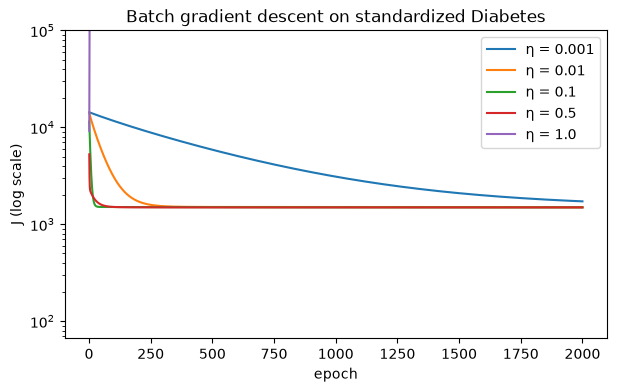

,η,final J,final relative distance,first epoch with distance < 1e-3
0,0.001,1723.402889,0.405113,not reached
1,0.010,1503.686676,0.334521,not reached
2,0.100,1491.892636,0.081792,not reached
3,0.500,1491.145907,0.000155,1524
4,1.000,diverged,diverged,not reached


In [16]:
num_epochs = 2000
etas = [0.001, 0.01, 0.1, 0.5, 1.0]
rows = []

plt.figure(figsize=(7, 4))
for eta in etas:
    w, J_history, dist_history = gradient_descent(X_train, y_train, eta, num_epochs, w_star)

    diverged = np.isnan(J_history[-1]) or J_history[-1] > J_history[0]
    reached = np.where(dist_history < 1e-3)[0]
    first_epoch = int(reached[0]) + 1 if len(reached) > 0 else "not reached"

    plt.semilogy(np.arange(1, num_epochs + 1), J_history, label=f"η = {eta}")
    rows.append({"η": eta,
                 "final J": "diverged" if diverged else J_history[-1],
                 "final relative distance": "diverged" if diverged else dist_history[-1],
                 "first epoch with distance < 1e-3": first_epoch})

plt.ylim(top=1e5)
plt.xlabel("epoch")
plt.ylabel("J (log scale)")
plt.title("Batch gradient descent on standardized Diabetes")
plt.legend()
plt.show()

pd.DataFrame(rows)

**Interpretation.** η = 0.001 and 0.01 are stable but far too slow: after 2000 epochs they are still at relative distance 0.41 and 0.33. η = 0.1 is much closer (0.08) but does not reach 1e-3. η = 0.5 is the only run that reaches 1e-3 (at epoch 1524) and ends at the optimal J ≈ 1491.15. η = 1.0 is the only one that diverges: J grows without bound. A larger step is faster until it crosses the stability threshold, which is computed in part (b).|